In [1]:
# Youth Political Participation & Democracy Analysis
# European Social Survey Round 11 (2023/24)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd

df = pd.read_csv("/content/youth_political_participation_cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (50116, 12)


,Country,Respondent_ID,Age,Age_Group,Gender,Education,Political_Interest,Trust_Politicians,Voted_Last_Election,Contacted_Politician,Online_Political_Activity,Analysis_Weight
0,Austria,50014,65,Older Adults (30+),Male,Lower-tier upper secondary,Very interested,5.00,Yes,No,No,0.13
1,Austria,50030,21,Young Adults (18-29),Female,Advanced vocational / sub-degree,Quite interested,1.00,Yes,No,No,0.11
2,Austria,50057,53,Older Adults (30+),Female,Bachelor-level tertiary,Quite interested,4.00,Yes,Yes,Yes,1.32
3,Austria,50106,78,Older Adults (30+),Female,Advanced vocational / sub-degree,Hardly interested,3.00,No,No,No,0.06
4,Austria,50145,64,Older Adults (30+),Male,Lower-tier upper secondary,Quite interested,5.00,Yes,No,No,0.35



Column names:
['Country', 'Respondent_ID', 'Age', 'Age_Group', 'Gender', 'Education', 'Political_Interest', 'Trust_Politicians', 'Voted_Last_Election', 'Contacted_Politician', 'Online_Political_Activity', 'Analysis_Weight']


In [3]:
# 1. Check data types and missing values
print("DATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isna().sum())

print("\nDUPLICATE RESPONDENT IDs")
print(df["Respondent_ID"].duplicated().sum())

print("\nAGE GROUP COUNTS")
print(df["Age_Group"].value_counts())

print("\nAGE RANGE")
print(df["Age"].min(), "to", df["Age"].max())

DATA TYPES
Country                       object
Respondent_ID                  int64
Age                            int64
Age_Group                     object
Gender                        object
Education                     object
Political_Interest            object
Trust_Politicians            float64
Voted_Last_Election           object
Contacted_Politician          object
Online_Political_Activity     object
Analysis_Weight              float64
dtype: object

MISSING VALUES
Country                         0
Respondent_ID                   0
Age                             0
Age_Group                    1457
Gender                          0
Education                     382
Political_Interest             95
Trust_Politicians             779
Voted_Last_Election           495
Contacted_Politician          310
Online_Political_Activity     249
Analysis_Weight                 0
dtype: int64

DUPLICATE RESPONDENT IDs
25270

AGE GROUP COUNTS
Age_Group
Older Adults (30+)      42266
Youn

In [4]:
# Rebuild age groups directly from Age
df["Age_Group"] = np.select(
    [
        df["Age"].between(18, 29),
        df["Age"].between(30, 98)
    ],
    [
        "Young Adults (18-29)",
        "Older Adults (30+)"
    ],
    default=None
)

# Keep eligible ages for the main comparison
analysis_df = df[df["Age_Group"].notna()].copy()

print("Total respondents:", len(df))
print("Respondents included in age comparisons:", len(analysis_df))
print("\nAge-group counts:")
print(analysis_df["Age_Group"].value_counts())

print("\nAge range in analysis:")
print(analysis_df["Age"].min(), "to", analysis_df["Age"].max())

Total respondents: 50116
Respondents included in age comparisons: 48659

Age-group counts:
Age_Group
Older Adults (30+)      42266
Young Adults (18-29)     6393
Name: count, dtype: int64

Age range in analysis:
18 to 90


In [5]:
# Compare political participation across age groups

variables = {
    "Political_Interest": "Political interest",
    "Voted_Last_Election": "Voted in last election",
    "Contacted_Politician": "Contacted a politician",
    "Online_Political_Activity": "Online political activity"
}

for column, title in variables.items():
    print(f"\n{'=' * 55}")
    print(title.upper())
    print("=" * 55)

    results = pd.crosstab(
        analysis_df["Age_Group"],
        analysis_df[column],
        normalize="index"
    ).mul(100).round(2)

    print(results)

# Average trust in politicians
print("\nAVERAGE TRUST IN POLITICIANS (0–10)")
print(
    analysis_df.groupby("Age_Group")["Trust_Politicians"]
    .mean()
    .round(2)
)


POLITICAL INTEREST
Political_Interest    Hardly interested  Not at all interested  \
Age_Group                                                        
Older Adults (30+)                34.21                  19.42   
Young Adults (18-29)              39.83                  27.62   

Political_Interest    Quite interested  Very interested  
Age_Group                                                
Older Adults (30+)               34.09            12.28  
Young Adults (18-29)             25.36             7.19  

VOTED IN LAST ELECTION
Voted_Last_Election     No  Not eligible   Yes
Age_Group                                     
Older Adults (30+)   19.16          2.96 77.89
Young Adults (18-29) 30.11         15.84 54.05

CONTACTED A POLITICIAN
Contacted_Politician    No   Yes
Age_Group                       
Older Adults (30+)   84.42 15.58
Young Adults (18-29) 91.51  8.49

ONLINE POLITICAL ACTIVITY
Online_Political_Activity    No   Yes
Age_Group                            
Older Adults

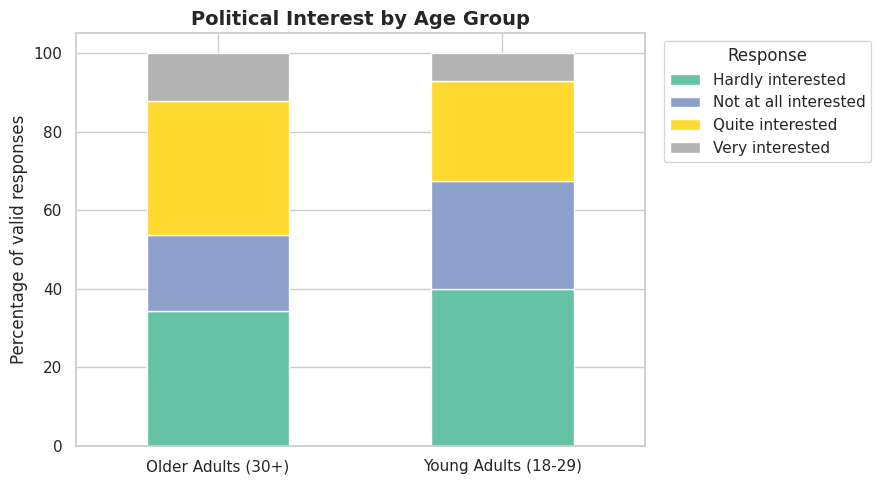

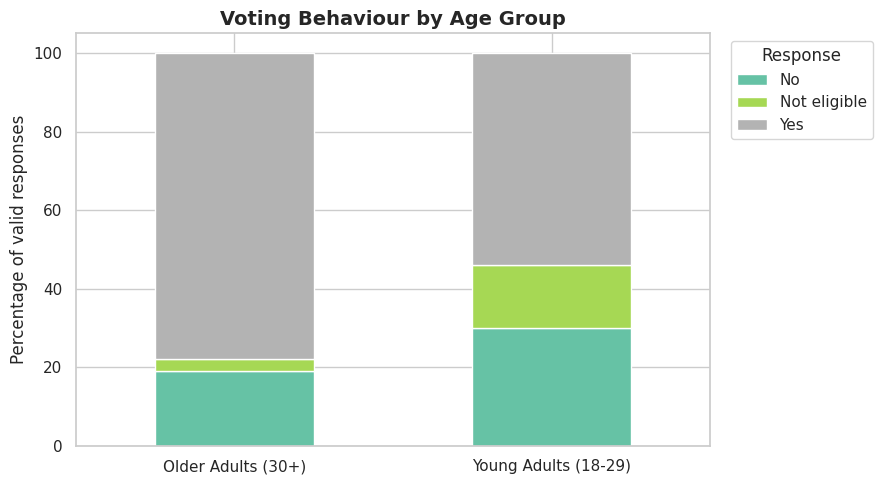

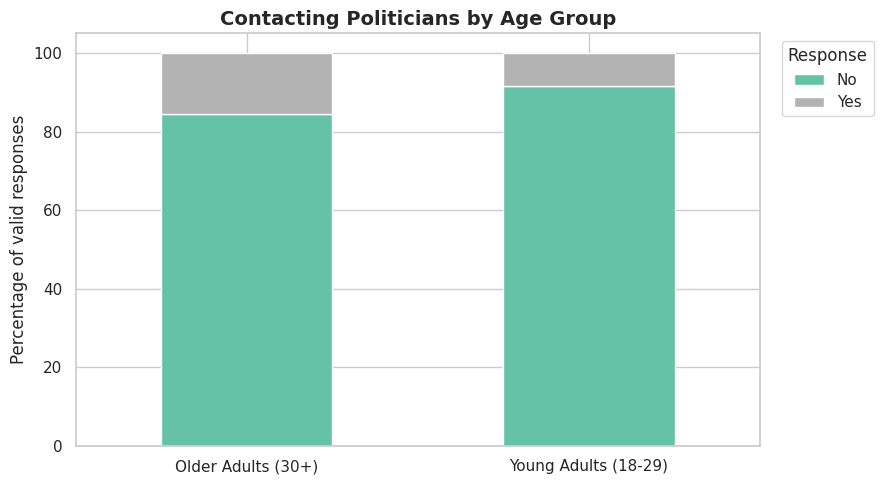

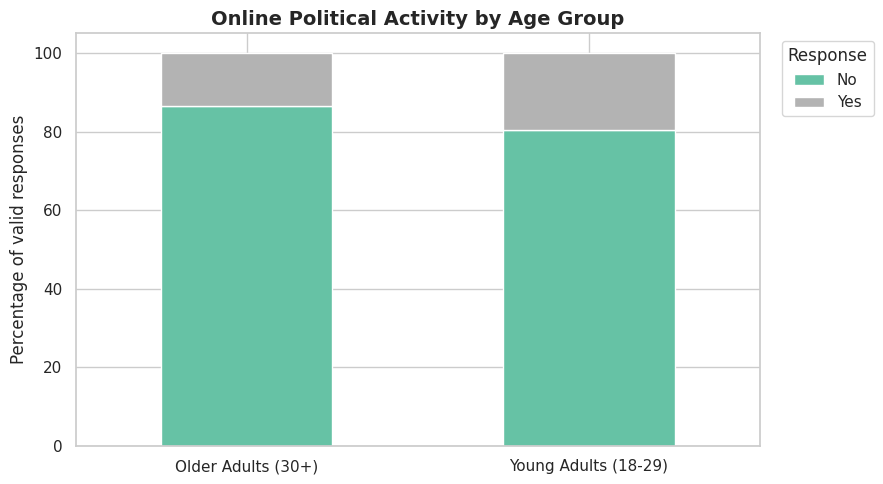

In [6]:
sns.set_theme(style="whitegrid")

# Outcomes to visualise
chart_variables = [
    ("Political_Interest", "Political Interest by Age Group"),
    ("Voted_Last_Election", "Voting Behaviour by Age Group"),
    ("Contacted_Politician", "Contacting Politicians by Age Group"),
    ("Online_Political_Activity", "Online Political Activity by Age Group")
]

for column, title in chart_variables:
    plot_data = pd.crosstab(
        analysis_df["Age_Group"],
        analysis_df[column],
        normalize="index"
    ) * 100

    ax = plot_data.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 5),
        colormap="Set2",
        edgecolor="white"
    )

    ax.set_title(title, fontsize=14, weight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Percentage of valid responses")
    ax.legend(title="Response", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

,count,mean,median
Age_Group,,,
Older Adults (30+),41694,3.49,3.00
Young Adults (18-29),6250,3.59,4.00


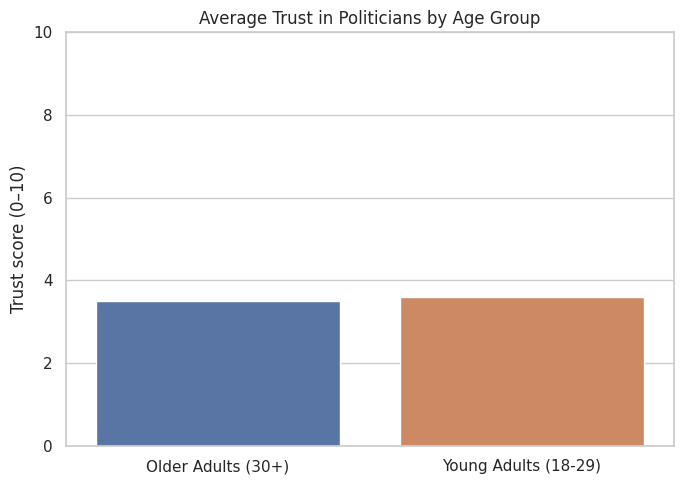

In [7]:
# Average trust in politicians by age group
trust_summary = (
    analysis_df.groupby("Age_Group")["Trust_Politicians"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(trust_summary)

plt.figure(figsize=(7, 5))
sns.barplot(
    data=analysis_df,
    x="Age_Group",
    y="Trust_Politicians",
    errorbar=None,
    hue="Age_Group",
    legend=False
)
plt.title("Average Trust in Politicians by Age Group")
plt.xlabel("")
plt.ylabel("Trust score (0–10)")
plt.ylim(0, 10)
plt.tight_layout()
plt.show()

In [9]:
# Create summary tables and export them
from google.colab import files

# Political interest percentages by age group
political_interest_summary = pd.crosstab(
    analysis_df["Age_Group"],
    analysis_df["Political_Interest"],
    normalize="index"
).mul(100).round(2)

# Trust in politicians
trust_summary = (
    analysis_df.groupby("Age_Group")["Trust_Politicians"]
    .agg(["count", "mean", "median"])
    .round(2)
)

# Export both tables
political_interest_summary.to_csv("political_interest_summary.csv")
trust_summary.to_csv("trust_summary.csv")

print("Both summary tables created and saved.")
display(political_interest_summary)
display(trust_summary)

Both summary tables created and saved.


Political_Interest,Hardly interested,Not at all interested,Quite interested,Very interested
Age_Group,,,,
Older Adults (30+),34.21,19.42,34.09,12.28
Young Adults (18-29),39.83,27.62,25.36,7.19


,count,mean,median
Age_Group,,,
Older Adults (30+),41694,3.49,3.00
Young Adults (18-29),6250,3.59,4.00


In [10]:
from google.colab import files

files.download("political_interest_summary.csv")
files.download("trust_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import matplotlib.pyplot as plt
import os

os.makedirs("charts", exist_ok=True)

for i, fig_num in enumerate(plt.get_fignums(), start=1):
    plt.figure(fig_num)
    plt.savefig(
        f"charts/chart_{i}.png",
        dpi=300,
        bbox_inches="tight"
    )

print("Charts exported.")

Charts exported.


In [12]:
import shutil
from google.colab import files

shutil.make_archive("youth_participation_charts", "zip", "charts")
files.download("youth_participation_charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>